# **CMSC 320 Final Project Checkpoint 2:**

# **Data Cleaning/Processing and Simple Analysis**

## Part 1.1: Data Preprocessing - Cleaning the Stock_Price.csv (stock_df dataframe)

In [1]:
import pandas as pd
from datetime import datetime
import string
pd.set_option('display.float_format', lambda x: f'{x:.2f}')

#load the csv of product stock and product info
stock_df = pd.read_csv("Stock_Price.csv")
product_df = pd.read_csv("Product_Info.csv")

In [2]:
stock_df.head() # view format of original dataframe before preprocessing

,ID,Company_Name,Sector,Industry,Nation,City,Market_Value,Current_Price,Previous_Close,52W_Low,52W_High,Description,CEO,Website
0,0,"Amazon.com, Inc.",Consumer Cyclical,Internet Retail United States,United States,Seattle,"$2,379,000,578,048",$222.54,226.19,161.38,258.60,"Amazon.com, Inc. eng...",NaN,NaN
1,1,ASUSTeK Computer Inc.,Technology,Computer Hardware,Taiwan,Taipei,"$435,257,507,840",$586.00,584.00,441.00,745.00,ASUSTeK Computer Inc...,Mr. Chongtang Shi,https://www.asus.com
2,6,Intel Corporation,Technology,Semiconductors,United States,Santa Clara,"$178,922,684,416",$37.51,37.81,17.67,44.02,Intel Corporation de...,Mr. Lip-Bu Tan,https://www.intel.com
3,7,HP Inc.,Technology,Computer Hardware,United States,Palo Alto,"$22,890,848,256",$24.49,24.74,21.21,35.28,HP Inc. provides per...,Mr. Enrique J. Lores,https://www.hp.com
4,8,Dell Technologies Inc.,Technology,Computer Hardware,United States,Round Rock,"$87,467,827,200",$130.51,129.98,66.25,168.08,Dell Technologies In...,Mr. Michael Saul Dell,https://www.dell.com


In [3]:
#cleaning stock

# value_counts() output shows that both Taipei and New Taipei City exist as a City in the dataset
print(stock_df["City"].value_counts())

#make City - taipei and new taipei city just New Taipei City
stock_df["City"] = stock_df["City"].replace("Taipei", "New Taipei City")

# value_counts() output shows that both Internet Retail United States and Internet Retail exist in the dataset
print(stock_df["Industry"].value_counts())

#make Industry - Internet Retail United States to Internet Retail
stock_df["Industry"] = stock_df["Industry"].replace("Internet Retail United States", "Internet Retail")

#Remove Sector, Website, CEO, Description columns

stock_df = stock_df.drop(columns=["Sector", "Website", "CEO", "Description", "ID"])
stock_df["Past_Year_Low"] = stock_df["52W_Low"]
stock_df = stock_df.drop(columns="52W_Low")
stock_df["Past_Year_High"] = stock_df["52W_High"]
stock_df = stock_df.drop(columns="52W_High")

#Remove dollar signs, make all dollar values floats

stock_df ["Market_Value"] = (stock_df["Market_Value"]
    .str.replace("$", "", regex=False)
    .str.replace(",", "", regex=False)
    .str.strip()
    .astype(float))

stock_df ["Current_Price"] = (stock_df["Current_Price"]
    .str.replace("$", "", regex=False)
    .str.replace(",", "", regex=False)
    .str.strip()
    .astype(float))

#remove duplicate rows
stock_df.drop_duplicates(inplace=True)

#Display the dataset
stock_df



City
Santa Clara        4
San Jose           3
Seattle            2
Palo Alto          2
New Taipei City    2
Cupertino          2
Taipei             1
Round Rock         1
Quarry Bay         1
Suwon              1
Tokyo              1
Redmond            1
Kadoma             1
Seoul              1
Milpitas           1
Lausanne           1
Mountain View      1
Name: count, dtype: int64
Industry
Computer Hardware                 11
Consumer Electronics               6
Semiconductors                     4
Internet Retail United States      1
Software - Infrastructure          1
Communication Equipment            1
Internet Content & Information     1
Internet Retail                    1
Name: count, dtype: int64


C:\Users\imart\AppData\Local\Temp\ipykernel_11664\2585049637.py:38: Pandas4Warning: The inplace keyword in DataFrame.drop_duplicates is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  stock_df.drop_duplicates(inplace=True)


,Company_Name,Industry,Nation,City,Market_Value,Current_Price,Previous_Close,Past_Year_Low,Past_Year_High
0,"Amazon.com, Inc.",Internet Retail,United States,Seattle,2379000578048.00,222.54,226.19,161.38,258.60
1,ASUSTeK Computer Inc.,Computer Hardware,Taiwan,New Taipei City,435257507840.00,586.00,584.00,441.00,745.00
2,Intel Corporation,Semiconductors,United States,Santa Clara,178922684416.00,37.51,37.81,17.67,44.02
3,HP Inc.,Computer Hardware,United States,Palo Alto,22890848256.00,24.49,24.74,21.21,35.28
4,Dell Technologies Inc.,Computer Hardware,United States,Round Rock,87467827200.00,130.51,129.98,66.25,168.08
5,Lenovo Group Limited,Computer Hardware,Hong Kong,Quarry Bay,15170897920.00,24.46,24.50,17.84,35.09
6,Acer Incorporated,Computer Hardware,Taiwan,New Taipei City,79514206208.00,26.45,26.70,26.20,40.95
7,Apple Inc.,Consumer Electronics,United States,Cupertino,4067898949632.00,274.11,278.28,169.21,288.62
9,"Samsung Electronics Co., Ltd.",Consumer Electronics,South Korea,Suwon,687329320632320.00,102800.00,104800.00,50800.00,112400.00
10,Sony Group Corporation,Consumer Electronics,Japan,Tokyo,158866636800.00,26.64,26.77,19.85,30.34


In [4]:
# Verifying that there are no NaN values
print(stock_df.isna().sum())

Company_Name      0
Industry          0
Nation            0
City              0
Market_Value      0
Current_Price     0
Previous_Close    0
Past_Year_Low     0
Past_Year_High    0
dtype: int64


## Part 1.2: Data Preprocessing - Cleaning the Product_Info.csv (product_df dataframe)

In [5]:
# view format of original dataframe before preprocessing
print(product_df.columns)
product_df.head()

Index(['id', 'prices.amountMax', 'prices.amountMin', 'prices.availability',
       'prices.condition', 'prices.currency', 'prices.dateSeen',
       'prices.isSale', 'prices.merchant', 'prices.shipping',
       'prices.sourceURLs', 'asins', 'brand', 'categories', 'dateAdded',
       'dateUpdated', 'ean', 'keys', 'manufacturer', 'manufacturerNumber',
       'name', 'primaryCategories', 'upc', 'weight'],
      dtype='str')


,id,prices.amountMax,prices.amountMin,prices.availability,prices.condition,prices.currency,prices.dateSeen,prices.isSale,prices.merchant,prices.shipping,...,dateAdded,dateUpdated,ean,keys,manufacturer,manufacturerNumber,name,primaryCategories,upc,weight
0,AWOpOCd2YSSHbkXw07ei,224.99,224.99,TRUE,new,USD,2018-05-26T13:00:00Z,True,Bestbuy.com,NaN,...,2018-05-28T23:46:50Z,2018-06-13T20:10:22Z,NaN,"887276057491,samsung850pro512gbinternalsataiii...",NaN,MZ-7KE512BW,Samsung - 850 PRO 512GB Internal SATA III Soli...,Electronics,8.87E+11,0.14 ounces
1,AWOpOCd2YSSHbkXw07ei,249.99,249.99,TRUE,new,USD,2018-05-26T13:00:00Z,False,Bestbuy.com,NaN,...,2018-05-28T23:46:50Z,2018-06-13T20:10:22Z,NaN,"887276057491,samsung850pro512gbinternalsataiii...",NaN,MZ-7KE512BW,Samsung - 850 PRO 512GB Internal SATA III Soli...,Electronics,8.87E+11,0.14 ounces
2,AV2Z1Efc-jtxr-f39lm6,139.99,139.99,Yes,New,USD,"2017-07-31T23:00:00Z,2017-07-26T21:00:00Z",False,Bestbuy.com,NaN,...,2017-07-31T18:06:52Z,2018-07-03T20:39:59Z,NaN,"corsair/cmk16gx4m2b3000c15,843591070010,corsai...",NaN,CMK16GX4M2B3000C15,Corsair Vengeance LPX 16GB (2x8GB) DDR4 DRAM 3...,Electronics,8.44E+11,3.2 ounces
3,AV2Z1Efc-jtxr-f39lm6,162.99,162.99,Yes,New,USD,2017-10-10T13:00:00Z,False,Bestbuy.com,NaN,...,2017-07-31T18:06:52Z,2018-07-03T20:39:59Z,NaN,"corsair/cmk16gx4m2b3000c15,843591070010,corsai...",NaN,CMK16GX4M2B3000C15,Corsair Vengeance LPX 16GB (2x8GB) DDR4 DRAM 3...,Electronics,8.44E+11,3.2 ounces
4,AV2Z1Efc-jtxr-f39lm6,189.99,189.99,TRUE,new,USD,2018-05-26T08:00:00Z,False,Bestbuy.com,NaN,...,2017-07-31T18:06:52Z,2018-07-03T20:39:59Z,NaN,"corsair/cmk16gx4m2b3000c15,843591070010,corsai...",NaN,CMK16GX4M2B3000C15,Corsair Vengeance LPX 16GB (2x8GB) DDR4 DRAM 3...,Electronics,8.44E+11,3.2 ounces


In [6]:
#reorder brand column to be first column in csv, and remove non essential columns
product_df = product_df[["brand", "prices.amountMax", "prices.amountMin", "prices.availability", "prices.condition", "prices.currency", "prices.merchant", "categories", "dateAdded", "dateUpdated", "name"]]

print("Value Counts Before Standardizing Values:")
print(product_df["prices.condition"].value_counts())
print(product_df["prices.availability"].value_counts())

#standardize prices.availability and price condition

product_df["prices.condition"] = product_df["prices.condition"].replace(["New", "New other (see details)"], "new")
product_df["prices.condition"] = product_df["prices.condition"].replace(["Refurbished", "Used", "used", "Seller refurbished", "Manufacturer refurbished", "pre-owned", "For parts or not working"], "refurbished")

product_df["prices.condition"] = product_df["prices.condition"].replace("Magnet - Neodymium, SearsCondition - Refurbished, Refresh Rate - 4Hz - 100kHz, Headphone Type - Over the Head, Driver Unit - 70mm, Power " \
"Handling (Watts) - 2000mW, Plug Type - 3.5mm, Audio Accessories - Headphones, Headphone Uses - Audiophile; iPod, Color - Black; Black, Impedance - 70 ohm, Cable Length - 6 - 6.99 Feet; 9 - 9.99 Feet, Sensitivity - " \
"102dB, Headphone Styles - Over-ear", "refurbished")

product_df["prices.availability"] = product_df["prices.availability"].replace(["TRUE", "yes", "Yes", "In Stock", "Special Order", "Limited Stock"], "in stock")
product_df["prices.availability"] = product_df["prices.availability"].replace(["no", "No", "Discontinued", "Not In Stock", "More on the Way", "Out Of Stock", "sold"], "out of stock")
product_df["prices.availability"] = product_df["prices.availability"].replace("undefined", "unknown")

# Fill NaN values in categorial data columns with "unknown"
categorical_cols = ["brand", "prices.availability", "prices.condition", "prices.merchant", "categories"]
product_df[categorical_cols] = (product_df[categorical_cols].fillna("unknown"))

Value Counts Before Standardizing Values:
prices.condition
New                                                                                                                                                                                                                                                                                                                                                                                                  4834
new                                                                                                                                                                                                                                                                                                                                                                                                   529
Used                                                                                                                                                     

In [7]:
print("\nValue Counts After Standardizing Values:")
print(product_df["prices.condition"].value_counts())
print(product_df["prices.availability"].value_counts())


Value Counts After Standardizing Values:
prices.condition
new            5528
unknown         617
refurbished     465
Name: count, dtype: int64
prices.availability
in stock        5643
unknown          754
out of stock     213
Name: count, dtype: int64


In [8]:
print("stock_df company names:")
print(stock_df["Company_Name"].unique())

print("\nproduct_df company names:")
print(product_df["brand"].unique())

stock_df company names:
<StringArray>
[                  'Amazon.com, Inc.',              'ASUSTeK Computer Inc.',
                  'Intel Corporation',                            'HP Inc.',
             'Dell Technologies Inc.',               'Lenovo Group Limited',
                  'Acer Incorporated',                         'Apple Inc.',
      'Samsung Electronics Co., Ltd.',             'Sony Group Corporation',
 'Micro-Star International Co., Ltd.',              'Microsoft Corporation',
     'Panasonic Holdings Corporation',                'LG Electronics Inc.',
       'Advanced Micro Devices, Inc.',               'Corsair Gaming, Inc.',
        'Western Digital Corporation',        'Logitech International S.A.',
                 'NVIDIA Corporation',                      'NETGEAR, Inc.',
                      'Alphabet Inc.']
Length: 21, dtype: str

product_df company names:
<StringArray>
[        'Samsung',         'Corsair',              'WD',       'Microsoft',
   'Ultimate

In [9]:
#standardize company names across the two datasets

# Maps from original brand names in product_df to their corresponding equivalents in stock_df
brand_mappings = {
    "amazon" : "Amazon.com, Inc.",
    "asus": "ASUSTeK Computer Inc.",
    "intel": "Intel Corporation",
    "hp": "HP Inc.",
    "dell": "Dell Technologies Inc.",
    "lenovo": "Lenovo Group Limited",
    "acer": "Acer Incorporated",
    "apple": "Apple Inc.",
    "samsung": "Samsung Electronics Co., Ltd.",
    "sony": "Sony Group Corporation",
    "msi": "Micro-Star International Co., Ltd.",
    "microsoft": "Microsoft Corporation",
    "lg": "LG Electronics Inc.",
    "amd": "Advanced Micro Devices, Inc.",
    "corsair": "Corsair Gaming, Inc.",
    "western digital": "Western Digital Corporation",
    "wd": "Western Digital Corporation",
    "logitech": "Logitech International S.A.",
    "nvidia": "NVIDIA Corporation",
    "netgear": "NETGEAR, Inc.",
    "google": "Alphabet Inc.",
    "panasonic": "Panasonic Holdings Corporation"
}

product_df["brand"] = product_df["brand"].str.lower().replace(brand_mappings)

#remove all products not produced by the focused on companies
product_df = product_df[product_df["brand"].isin(stock_df["Company_Name"])].reset_index(drop=True)

#remove all products not in usd
product_df = product_df[product_df["prices.currency"] == "USD"].reset_index(drop=True)

print("product_df new company names:")
print(product_df["brand"].unique())

product_df.head(10)

product_df new company names:
<StringArray>
[     'Samsung Electronics Co., Ltd.',               'Corsair Gaming, Inc.',
        'Western Digital Corporation',              'Microsoft Corporation',
                         'Apple Inc.',               'Lenovo Group Limited',
             'Sony Group Corporation',        'Logitech International S.A.',
              'ASUSTeK Computer Inc.',             'Dell Technologies Inc.',
                      'NETGEAR, Inc.',     'Panasonic Holdings Corporation',
                'LG Electronics Inc.', 'Micro-Star International Co., Ltd.',
                  'Acer Incorporated',                            'HP Inc.',
                 'NVIDIA Corporation',                  'Intel Corporation',
                      'Alphabet Inc.',                   'Amazon.com, Inc.',
       'Advanced Micro Devices, Inc.']
Length: 21, dtype: str


,brand,prices.amountMax,prices.amountMin,prices.availability,prices.condition,prices.currency,prices.merchant,categories,dateAdded,dateUpdated,name
0,"Samsung Electronics Co., Ltd.",224.99,224.99,in stock,new,USD,Bestbuy.com,"Internal Solid State Drives,Solid State Drives...",2018-05-28T23:46:50Z,2018-06-13T20:10:22Z,Samsung - 850 PRO 512GB Internal SATA III Soli...
1,"Samsung Electronics Co., Ltd.",249.99,249.99,in stock,new,USD,Bestbuy.com,"Internal Solid State Drives,Solid State Drives...",2018-05-28T23:46:50Z,2018-06-13T20:10:22Z,Samsung - 850 PRO 512GB Internal SATA III Soli...
2,"Corsair Gaming, Inc.",139.99,139.99,in stock,new,USD,Bestbuy.com,"Computers,Memory (RAM),Computers & Accessories...",2017-07-31T18:06:52Z,2018-07-03T20:39:59Z,Corsair Vengeance LPX 16GB (2x8GB) DDR4 DRAM 3...
3,"Corsair Gaming, Inc.",162.99,162.99,in stock,new,USD,Bestbuy.com,"Computers,Memory (RAM),Computers & Accessories...",2017-07-31T18:06:52Z,2018-07-03T20:39:59Z,Corsair Vengeance LPX 16GB (2x8GB) DDR4 DRAM 3...
4,"Corsair Gaming, Inc.",189.99,189.99,in stock,new,USD,Bestbuy.com,"Computers,Memory (RAM),Computers & Accessories...",2017-07-31T18:06:52Z,2018-07-03T20:39:59Z,Corsair Vengeance LPX 16GB (2x8GB) DDR4 DRAM 3...
5,"Corsair Gaming, Inc.",194.82,194.82,in stock,new,USD,Beach Audio Inc,"Computers,Memory (RAM),Computers & Accessories...",2017-07-31T18:06:52Z,2018-07-03T20:39:59Z,Corsair Vengeance LPX 16GB (2x8GB) DDR4 DRAM 3...
6,"Corsair Gaming, Inc.",149.99,149.99,in stock,new,USD,Bestbuy.com,"Computers,Memory (RAM),Computers & Accessories...",2017-07-31T18:06:52Z,2018-07-03T20:39:59Z,Corsair Vengeance LPX 16GB (2x8GB) DDR4 DRAM 3...
7,"Corsair Gaming, Inc.",147.99,147.99,in stock,new,USD,Bestbuy.com,"Computers,Memory (RAM),Computers & Accessories...",2017-07-31T18:06:52Z,2018-07-03T20:39:59Z,Corsair Vengeance LPX 16GB (2x8GB) DDR4 DRAM 3...
8,"Corsair Gaming, Inc.",158.95,158.95,in stock,new,USD,Alex Magic Electronics,"Computers,Memory (RAM),Computers & Accessories...",2017-07-31T18:06:52Z,2018-07-03T20:39:59Z,Corsair Vengeance LPX 16GB (2x8GB) DDR4 DRAM 3...
9,"Corsair Gaming, Inc.",154.99,154.99,in stock,new,USD,Bestbuy.com,"Computers,Memory (RAM),Computers & Accessories...",2017-07-31T18:06:52Z,2018-07-03T20:39:59Z,Corsair Vengeance LPX 16GB (2x8GB) DDR4 DRAM 3...


## Part 1.3: Data Procesing - Combining the two .csv files into one

In [10]:
combined_df = product_df.merge(stock_df, left_on="brand", right_on="Company_Name", how="inner")
combined_df = combined_df.drop(columns=["Company_Name"])

combined_df.head(10)

,brand,prices.amountMax,prices.amountMin,prices.availability,prices.condition,prices.currency,prices.merchant,categories,dateAdded,dateUpdated,name,Industry,Nation,City,Market_Value,Current_Price,Previous_Close,Past_Year_Low,Past_Year_High
0,"Samsung Electronics Co., Ltd.",224.99,224.99,in stock,new,USD,Bestbuy.com,"Internal Solid State Drives,Solid State Drives...",2018-05-28T23:46:50Z,2018-06-13T20:10:22Z,Samsung - 850 PRO 512GB Internal SATA III Soli...,Consumer Electronics,South Korea,Suwon,687329320632320.00,102800.00,104800.00,50800.00,112400.00
1,"Samsung Electronics Co., Ltd.",249.99,249.99,in stock,new,USD,Bestbuy.com,"Internal Solid State Drives,Solid State Drives...",2018-05-28T23:46:50Z,2018-06-13T20:10:22Z,Samsung - 850 PRO 512GB Internal SATA III Soli...,Consumer Electronics,South Korea,Suwon,687329320632320.00,102800.00,104800.00,50800.00,112400.00
2,"Corsair Gaming, Inc.",139.99,139.99,in stock,new,USD,Bestbuy.com,"Computers,Memory (RAM),Computers & Accessories...",2017-07-31T18:06:52Z,2018-07-03T20:39:59Z,Corsair Vengeance LPX 16GB (2x8GB) DDR4 DRAM 3...,Computer Hardware,United States,Milpitas,662897792.00,6.22,6.20,5.35,13.02
3,"Corsair Gaming, Inc.",162.99,162.99,in stock,new,USD,Bestbuy.com,"Computers,Memory (RAM),Computers & Accessories...",2017-07-31T18:06:52Z,2018-07-03T20:39:59Z,Corsair Vengeance LPX 16GB (2x8GB) DDR4 DRAM 3...,Computer Hardware,United States,Milpitas,662897792.00,6.22,6.20,5.35,13.02
4,"Corsair Gaming, Inc.",189.99,189.99,in stock,new,USD,Bestbuy.com,"Computers,Memory (RAM),Computers & Accessories...",2017-07-31T18:06:52Z,2018-07-03T20:39:59Z,Corsair Vengeance LPX 16GB (2x8GB) DDR4 DRAM 3...,Computer Hardware,United States,Milpitas,662897792.00,6.22,6.20,5.35,13.02
5,"Corsair Gaming, Inc.",194.82,194.82,in stock,new,USD,Beach Audio Inc,"Computers,Memory (RAM),Computers & Accessories...",2017-07-31T18:06:52Z,2018-07-03T20:39:59Z,Corsair Vengeance LPX 16GB (2x8GB) DDR4 DRAM 3...,Computer Hardware,United States,Milpitas,662897792.00,6.22,6.20,5.35,13.02
6,"Corsair Gaming, Inc.",149.99,149.99,in stock,new,USD,Bestbuy.com,"Computers,Memory (RAM),Computers & Accessories...",2017-07-31T18:06:52Z,2018-07-03T20:39:59Z,Corsair Vengeance LPX 16GB (2x8GB) DDR4 DRAM 3...,Computer Hardware,United States,Milpitas,662897792.00,6.22,6.20,5.35,13.02
7,"Corsair Gaming, Inc.",147.99,147.99,in stock,new,USD,Bestbuy.com,"Computers,Memory (RAM),Computers & Accessories...",2017-07-31T18:06:52Z,2018-07-03T20:39:59Z,Corsair Vengeance LPX 16GB (2x8GB) DDR4 DRAM 3...,Computer Hardware,United States,Milpitas,662897792.00,6.22,6.20,5.35,13.02
8,"Corsair Gaming, Inc.",158.95,158.95,in stock,new,USD,Alex Magic Electronics,"Computers,Memory (RAM),Computers & Accessories...",2017-07-31T18:06:52Z,2018-07-03T20:39:59Z,Corsair Vengeance LPX 16GB (2x8GB) DDR4 DRAM 3...,Computer Hardware,United States,Milpitas,662897792.00,6.22,6.20,5.35,13.02
9,"Corsair Gaming, Inc.",154.99,154.99,in stock,new,USD,Bestbuy.com,"Computers,Memory (RAM),Computers & Accessories...",2017-07-31T18:06:52Z,2018-07-03T20:39:59Z,Corsair Vengeance LPX 16GB (2x8GB) DDR4 DRAM 3...,Computer Hardware,United States,Milpitas,662897792.00,6.22,6.20,5.35,13.02


## Part 2.1: Simple Analysis - 

count    6256.00
mean      750.81
std      1191.85
min         1.00
25%       127.99
50%       338.99
75%       949.24
max     19999.99
Name: avg_price, dtype: float64


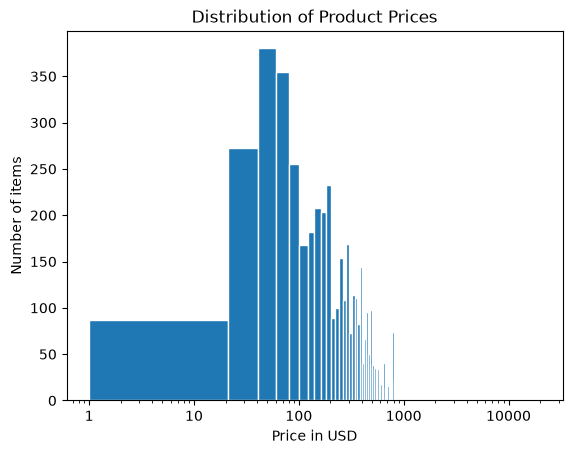

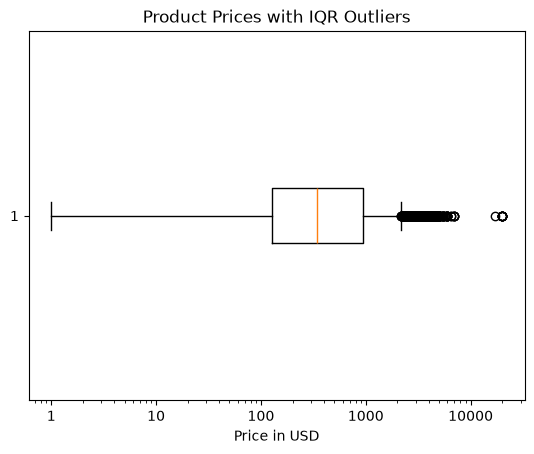

In [15]:
import numpy as np
import matplotlib.pyplot as plt
import scipy as sc

#calculate the average prive for each item
combined_df["avg_price"] = (combined_df["prices.amountMin"] + combined_df["prices.amountMax"]) / 2
price = combined_df["avg_price"]

#descriptive statistics for price 
print(price.describe())


plt.xscale("log")
plt.hist(price, bins= 1000, edgecolor="white")
plt.xscale("log")
plt.title("Distribution of Product Prices")
plt.xlabel("Price in USD")
plt.ylabel("Number of items")
plt.gca().xaxis.set_major_formatter(plt.ScalarFormatter())
plt.show()

plt.boxplot(price, orientation="horizontal")
plt.xscale("log")
plt.title("Product Prices with IQR Outliers")
plt.xlabel("Price in USD")
plt.gca().xaxis.set_major_formatter(plt.ScalarFormatter())
plt.show()

## Part 2.2: Exploratory Data Analysis - Is company market value/capitalization correlated with median product price?

brand
Intel Corporation                    1899.99
LG Electronics Inc.                  1796.99
Micro-Star International Co., Ltd.   1499.49
Dell Technologies Inc.                782.00
Advanced Micro Devices, Inc.          748.99
Name: avg_price, dtype: float64
brand
Samsung Electronics Co., Ltd.    687329320632320.00
LG Electronics Inc.               16764138160128.00
Panasonic Holdings Corporation     4794256195584.00
NVIDIA Corporation                 4292132732928.00
Apple Inc.                         4067898949632.00
Name: Market_Value, dtype: float64


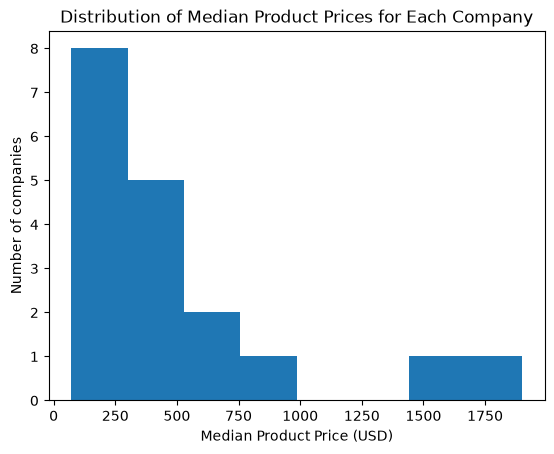

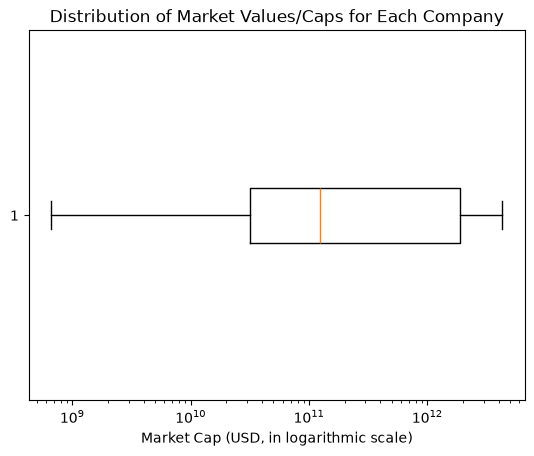

In [16]:
# Calculating median product prices for each company
median_product_prices = combined_df.groupby("brand")["avg_price"].median()

print(median_product_prices.sort_values(ascending=False).head())

# All rows for same brand have same market value because they were joined from Stock_Price.csv, so first() works here
market_values = combined_df.groupby("brand")["Market_Value"].first()

print(market_values.sort_values(ascending=False).head())

# These companies' market caps seem abnormally high, maybe in wrong currency, so excluding them from correlation analysis
exclude_companies = ["Samsung Electronics Co., Ltd.", "LG Electronics Inc.", "Panasonic Holdings Corporation"]

market_values = market_values.drop(exclude_companies)
median_product_prices = median_product_prices.drop(exclude_companies)

plt.hist(median_product_prices, bins = 8)
plt.title("Distribution of Median Product Prices for Each Company")
plt.xlabel("Median Product Price (USD)")
plt.ylabel("Number of companies")
plt.show()

plt.boxplot(market_values, orientation = "horizontal")
plt.title("Distribution of Market Values/Caps for Each Company")
plt.xscale("log")
plt.xlabel("Market Cap (USD, in logarithmic scale)")
plt.show()

We will use Spearman's rank correlation coefficient here instead of Pearson's correlation coeffcient. This is because the histogram above shows that there are large outliers in the median product prices. This would heavily affect the Pearson correlation coefficient, so it is better to use Spearman’s rank correlation which is non-parametric and much more resistant to these outliers. Additionally, the histogram shows that the median product prices are right skewed and not normally distributed, so the normality assumptions for using the p-value for Pearson's correlation coefficient don't apply. Since Spearman's rank correlation coefficient is non-parametric and doesn't require both variables to follow a normal distribution, we can still conduct a statistical significance test using the p-value for it.

Spearman's rank is slightly different from Pearson's coefficient because Pearson's coefficient measures linear relationships, while Spearman's rank measures monotonic relationships (variables generally move in same direction, but not necessarily a linear relationship). The Spearman rank coefficient $\rho_s$ is between [-1, 1], with 0 indicating no relationship and -1 or 1 indicating a strong negative/positive relationship.

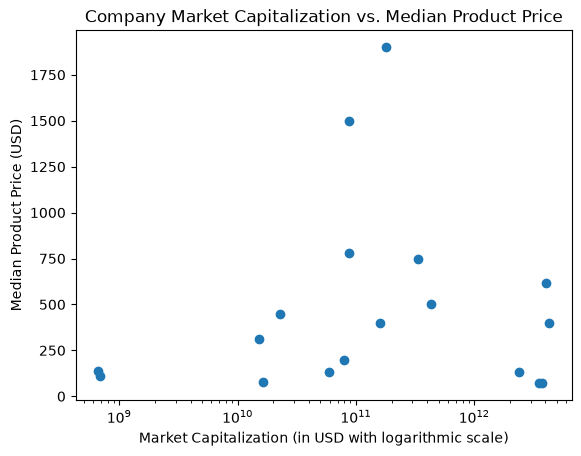

In [17]:
# Creating scatter plot to observe relationship between market cap and median product price

plt.scatter(x = market_values, y = median_product_prices)
plt.xscale("log") # using log scale so that graph is clearer since company values vary widely
plt.xlabel("Market Capitalization (in USD with logarithmic scale)")
plt.ylabel("Median Product Price (USD)")
plt.title("Company Market Capitalization vs. Median Product Price")
plt.show()

We will do a hypothesis test using alpha = 0.05. 

Our null and alternative hypotheses are

H0: There is no monotonic relationship between company market cap and median product price, or $\rho_s = 0$

HA: There is a monotonic relationship between company market cap and median product price, or $\rho_s \neq 0$

where $\rho_s$ is population Spearman rank correlation between company market capitalization and median product price

In [18]:
alpha = 0.05
res = sc.stats.spearmanr(market_values, median_product_prices)
print("Spearman correlation:", res.statistic)
print("P-value:", res.pvalue)

if res.pvalue >= alpha:
    print(f"The p-val > alpha = {alpha}, so we fail to reject the H0.")
    print("There is not sufficient evidence to conclude that there is " \
    "a monotonic relationship between company market cap and median product price.")
elif res.pvalue < alpha:
    print(f"The p-val < alpha = {alpha}, so we reject the H0.")
    print("There is sufficient evidence to conclude that there is a monotonic relationship " 
    "between company market cap and median product price.")

Spearman correlation: 0.13319568114711103
P-value: 0.5982701851593039
The p-val > alpha = 0.05, so we fail to reject the H0.
There is not sufficient evidence to conclude that there is a monotonic relationship between company market cap and median product price.


The positive Spearman correlation coefficient of 0.1332 suggests that there is a slight positive relationship between company market cap and median product price, but the p-value of 0.598 is greater than alpha = 0.05 so we fail to reject the null hypothesis. There is not sufficient statistical evidence to conclude that company market capitalization is monotonically associated with median product price.

## Part 2.3: Hypothesis Testing - Does the retailer affect product price?

Index(['Bestbuy.com', 'bhphotovideo.com', 'Walmart.com', 'Beach Camera'],
      dtype='str', name='prices.merchant')
prices.merchant
Bestbuy.com         1799
bhphotovideo.com    1223
Walmart.com          471
Beach Camera         245
Name: count, dtype: int64


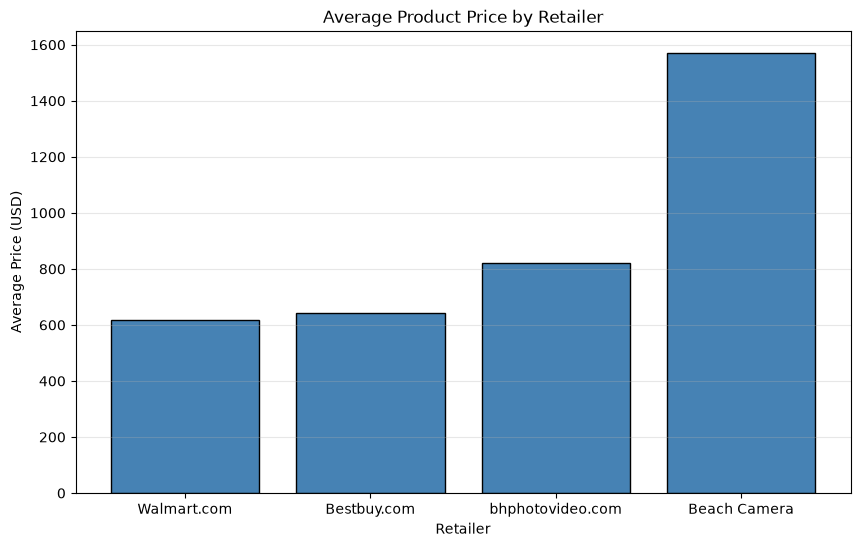

In [33]:
combined_df["prices.merchant"].value_counts().head(10)
retails = combined_df["prices.merchant"].value_counts().drop("unknown")
top_four = retails.head(4).index
print(top_four)
anova_df = combined_df[combined_df["prices.merchant"].isin(top_four)]
print(anova_df["prices.merchant"].value_counts())
names = []
groups = []
for name, group in anova_df.groupby("prices.merchant"):
    names.append(name)
    groups.append(group["avg_price"])

avg_prices = anova_df.groupby("prices.merchant")["avg_price"].mean().sort_values()

plt.figure(figsize=(10, 6))
plt.bar(avg_prices.index, avg_prices.values, color="steelblue", edgecolor="black")
plt.title("Average Product Price by Retailer")
plt.xlabel("Retailer")
plt.ylabel("Average Price (USD)")
plt.grid(axis="y", alpha=0.3)
plt.show()
    

We are using an ANOVA test because our hypothesis is whether retailer affects product price. We are comparing the average product price across four retailers in our dataset: Bestbuy.com, bhphotovideo.com, Walmart.com, and Beach Camera. Since we are comparing three or more groups, ANOVA is the appropriate test. However, in Part 2.1, we had a graph that showed the number of items at each price, and we see that it's heavily right-skewed, which shows that there are more cheap items than expensive items. This is a problem with ANOVA testing because it assumes that the groups are normally distributed, so to mitigate that, we used a log transformation on the prices before running the test.

We will do a hypothesis test using alpha = 0.05. 

Our null and alternative hypotheses are:

H0: The average product price is the same across all four retailers.

HA: At least one retailer’s average product price is different.

In [34]:
alpha = 0.05

logs_of_retails = []

for x in groups:
    logs_of_retails.append(np.log(x))

answer = sc.stats.f_oneway(*logs_of_retails)
print(f"F-statistic: {answer.statistic}")
print(f"P-value: {answer.pvalue}")


F-statistic: 67.69934790703232
P-value: 1.2645122040589945e-42


The ANOVA test produced an F-statistic of 67 and a p-value of 1.26e-42, which is 41 zeros after the decimal point. Since the p-value is less than alpha = 0.05, we reject the null hypothesis. There is sufficient statistical evidence to conclude that at least one retailer's mean product price differs from the others. Based on our bar chart, Beach Camera's much higher average price likely drives this difference, though this may reflect the types of products it sells rather than its pricing alone.